### 분석: 전체 데이터 파일, 각 폴더 파일 수 확인

In [3]:
import os
import json
import math
import random
import pandas as pd
from PIL import Image
from collections import Counter
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from collections import defaultdict
from matplotlib import font_manager
from itertools import combinations
from pathlib import Path

data_dir = "../data/raw"

folder_info = []

# data 바로 아래 폴더 3개만 탐색
for folder in os.listdir(data_dir):
    folder_path = os.path.join(data_dir, folder)

    if os.path.isdir(folder_path):
        file_count = sum(len(files) for _, _, files in os.walk(folder_path))

        folder_info.append({"폴더명": folder, "파일 수": file_count})

df = pd.DataFrame(folder_info)

print(f"전체 파일 수: {df['파일 수'].sum():,}개")
display(df)

전체 파일 수: 1,837개


,폴더명,파일 수
0,test_images,842
1,train_annotations,763
2,train_images,232


### 분석: 전체 데이터 이미지 크기가 동일한지 확인

In [5]:
for folder in ["train_images", "test_images"]:
    folder_path = os.path.join(data_dir, folder)
    image_sizes = []

    for root, dirs, files in os.walk(folder_path):
        for file in files:
            if file.lower().endswith((".jpg", ".jpeg", ".png")):
                with Image.open(os.path.join(root, file)) as img:
                    image_sizes.append(img.size)

    size_counts = Counter(image_sizes)

    print(f"\n[{folder}]")
    print(f"전체 이미지 수: {len(image_sizes):,}개")
    print(f"모든 이미지 크기 동일 여부: {len(size_counts) == 1}")

    for size, count in size_counts.most_common():
        print(f"  {size}: {count:,}개")


[train_images]
전체 이미지 수: 232개
모든 이미지 크기 동일 여부: True
  (976, 1280): 232개

[test_images]
전체 이미지 수: 842개
모든 이미지 크기 동일 여부: True
  (976, 1280): 842개


### 분석: 이미지와 어노테이션 사이의 매칭 누락이 있는지 확인

In [6]:
train_dir = "../data/raw/train_images"
annotation_dir = "../data/raw/train_annotations"

# 1. train_images 안의 실제 이미지 파일명 수집
image_files = set()

for root, dirs, files in os.walk(train_dir):
    for file in files:
        if file.lower().endswith((".png", ".jpg", ".jpeg")):
            image_files.add(file)

# 2. JSON 하나씩 확인하면서 매칭 여부 검사
total_json = 0
matched_json = 0
unmatched_json = []

for root, dirs, files in os.walk(annotation_dir):
    for file in files:
        if file.lower().endswith(".json"):
            total_json += 1
            json_path = os.path.join(root, file)

            with open(json_path, "r", encoding="utf-8") as f:
                data = json.load(f)

            # images 리스트에서 file_name 추출
            image_list = data.get("images", [])

            if len(image_list) == 0:
                unmatched_json.append((file, "images 정보 없음"))
                continue

            file_name = image_list[0].get("file_name")

            if file_name in image_files:
                matched_json += 1
            else:
                unmatched_json.append((file, file_name))

# 3. 결과 출력
print(f"전체 JSON 수: {total_json}개")
print(f"정상적으로 이미지와 매칭된 JSON 수: {matched_json}개")
print(f"매칭 실패한 JSON 수: {len(unmatched_json)}개")

if len(unmatched_json) == 0:
    print("\n✅ 763개의 JSON이 모두 train_images 안의 232개 이미지와 정상 매칭됩니다.")
else:
    print("\n⚠️ 매칭 실패한 JSON 예시:")
    for item in unmatched_json[:10]:
        print(item)

전체 JSON 수: 763개
정상적으로 이미지와 매칭된 JSON 수: 763개
매칭 실패한 JSON 수: 0개

✅ 763개의 JSON이 모두 train_images 안의 232개 이미지와 정상 매칭됩니다.


### 분석: Bounding Box 시각화(랜덤 4장)로 확인하기

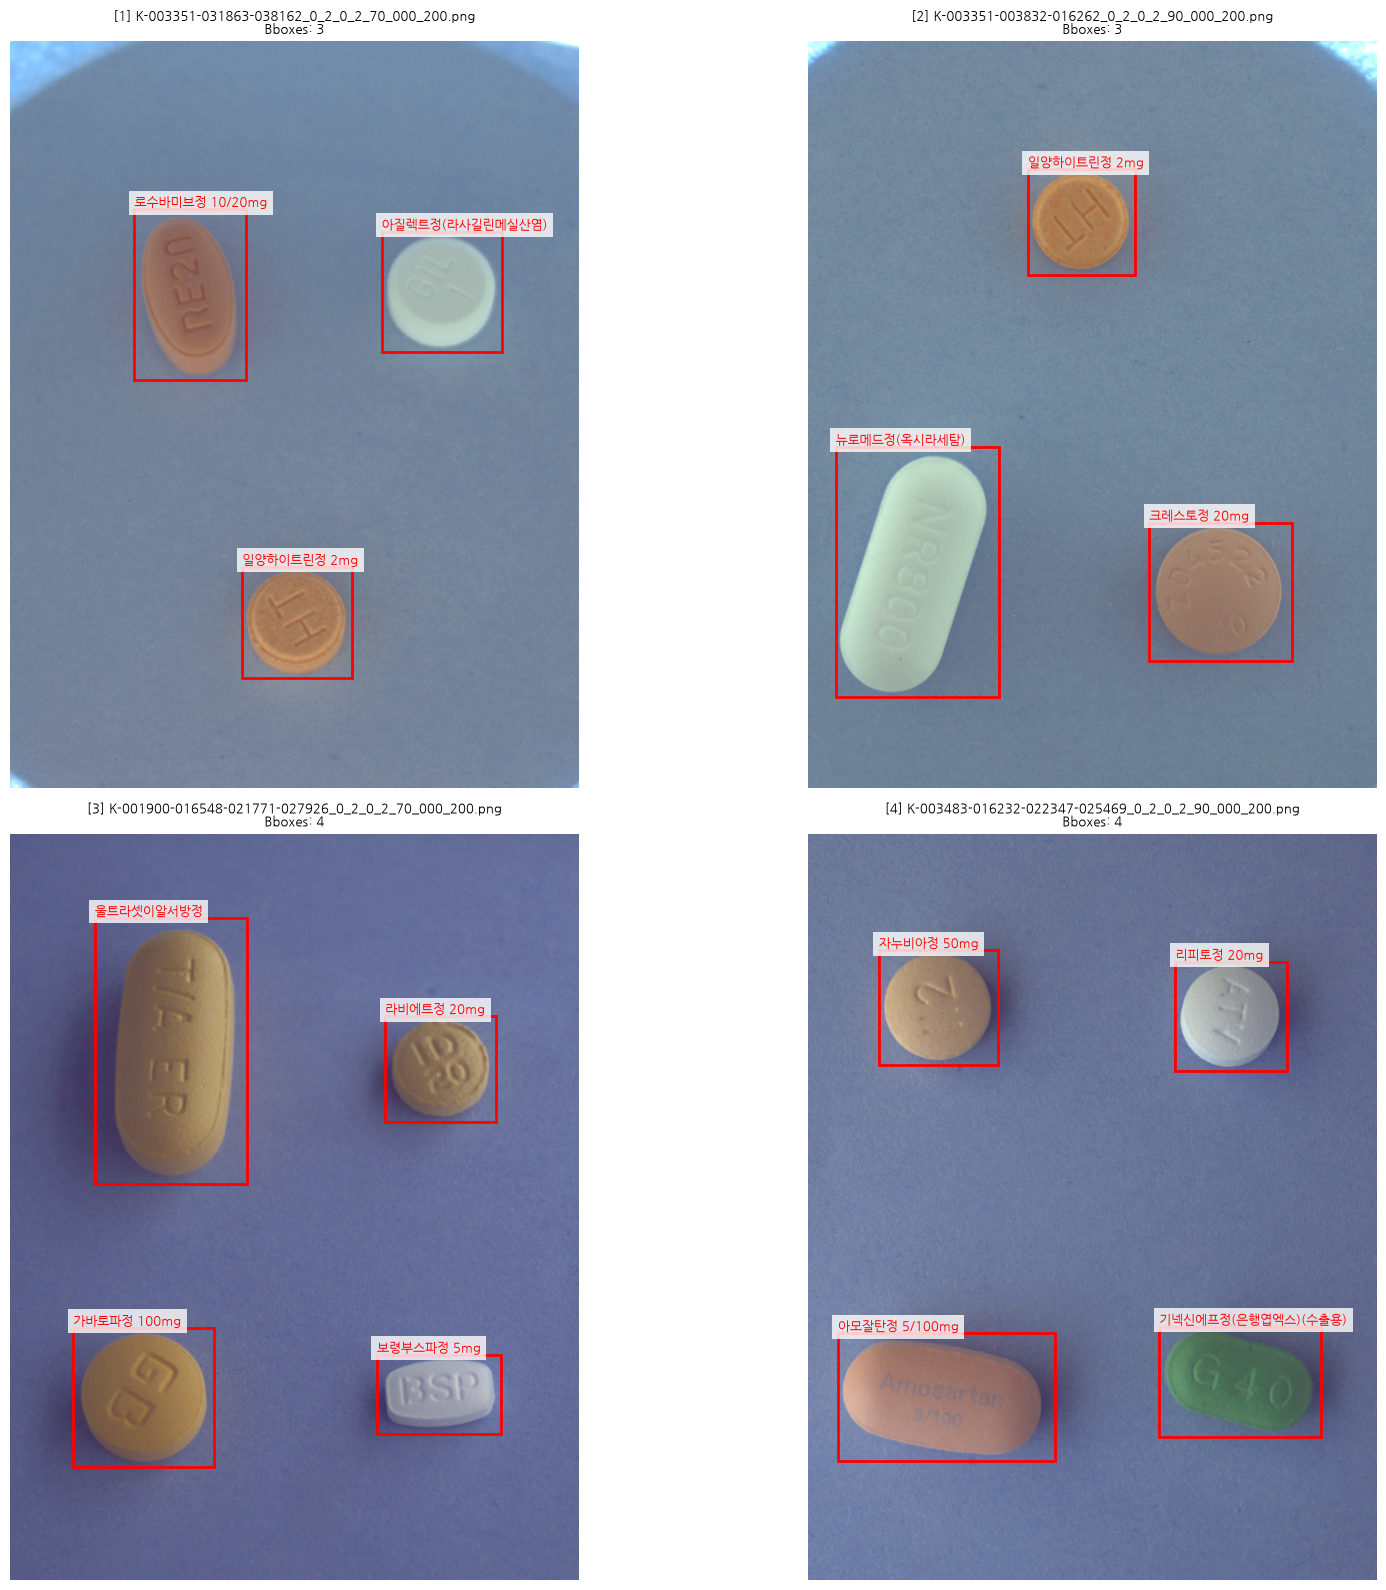

In [ ]:
# 리눅스 한글 폰트
font_path = Path("/usr/share/fonts/truetype/nanum/NanumGothic.ttf")
if not font_path.is_file():
    raise FileNotFoundError("터미널에서 sudo apt install fonts-nanum 을 실행하세요.")

font_manager.fontManager.addfont(str(font_path))
plt.rcParams["font.family"] = font_manager.FontProperties(fname=str(font_path)).get_name()
plt.rcParams["axes.unicode_minus"] = False

# 데이터 경로
root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
data_dir = root / "data" / "raw"

image_paths = {
    path.name: path
    for path in (data_dir / "train_images").rglob("*")
    if path.is_file() and path.suffix.lower() in {".png", ".jpg", ".jpeg"}
}

# 이미지별 bbox와 약품명
image_annotations = defaultdict(list)

for path in (data_dir / "train_annotations").rglob("*.json"):
    with path.open(encoding="utf-8") as file:
        data = json.load(file)

    images = {img["id"]: img for img in data["images"]}

    for ann in data["annotations"]:
        img = images.get(ann["image_id"])
        bbox = ann.get("bbox")
        if img is None or not isinstance(bbox, list) or len(bbox) != 4:
            continue

        name = Path(img["file_name"]).name
        if name in image_paths:
            image_annotations[name].append((bbox, img.get("dl_name") or "Unknown"))

# seed 값을 바꾸면 다른 이미지 선택
seed = 42
samples = random.Random(seed).sample(sorted(image_annotations), min(4, len(image_annotations)))
if not samples:
    raise ValueError("이미지와 연결된 bbox가 없습니다. 데이터 경로를 확인하세요.")

fig, axes = plt.subplots(2, 2, figsize=(18, 16))

for ax in axes.flat:
    ax.axis("off")

for number, (ax, name) in enumerate(zip(axes.flat, samples), start=1):
    with Image.open(image_paths[name]) as img:
        ax.imshow(img.convert("RGB"))

    for (x, y, width, height), drug_name in image_annotations[name]:
        ax.add_patch(
            patches.Rectangle(
                (x, y),
                width,
                height,
                fill=False,
                edgecolor="red",
                linewidth=2,
            )
        )
        ax.text(
            x,
            max(0, y - 5),
            drug_name,
            fontsize=9,
            color="red",
            bbox={"facecolor": "white", "alpha": 0.8, "edgecolor": "none"},
        )

    ax.set_title(
        f"[{number}] {name}\nBboxes: {len(image_annotations[name])}",
        fontsize=9,
    )

plt.tight_layout()
plt.show()

### 분석: 학습 이미지 전체중 겹쳐지거나, 해당 이미지 밖에 찍힌 바운딩 박스 찾기

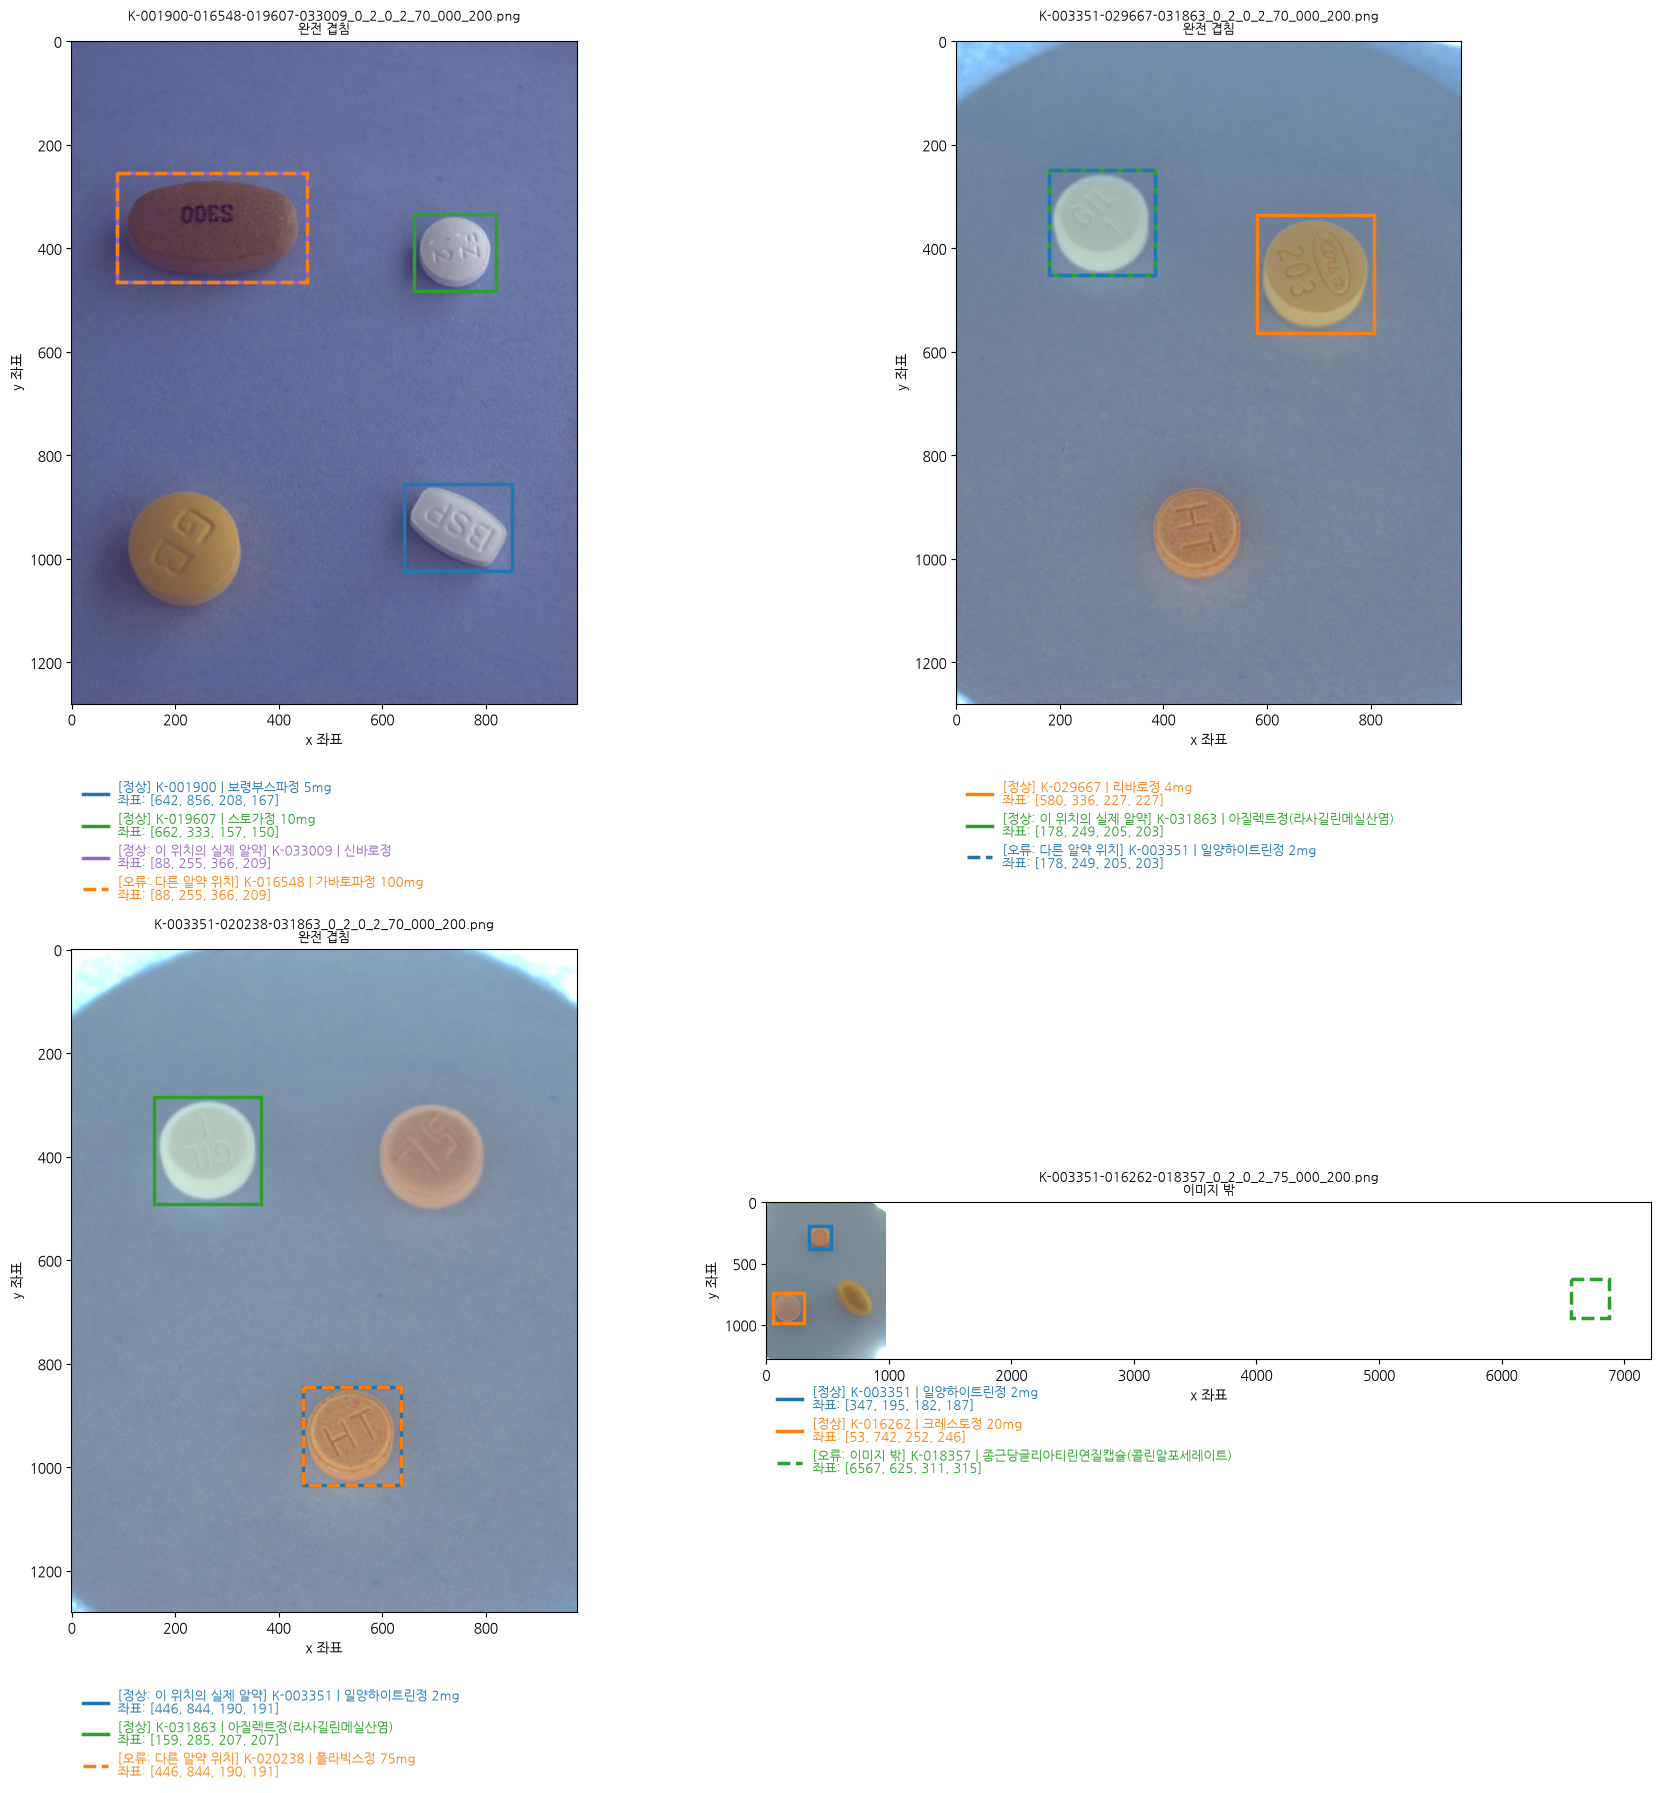

In [ ]:
root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
data_dir = root / "data" / "raw"

# 이미지명, 오류 약품, 정상 약품, 화면의 수정 전 좌표
targets = [
    (
        "K-001900-016548-019607-033009_0_2_0_2_70_000_200",
        "K-016548",
        "K-033009",
        [88, 255, 366, 209],
    ),
    (
        "K-003351-029667-031863_0_2_0_2_70_000_200",
        "K-003351",
        "K-031863",
        [178, 249, 205, 203],
    ),
    (
        "K-003351-020238-031863_0_2_0_2_70_000_200",
        "K-020238",
        "K-003351",
        [446, 844, 190, 191],
    ),
    (
        "K-003351-016262-018357_0_2_0_2_75_000_200",
        "K-018357",
        None,
        [6567, 625, 311, 315],
    ),
]

colors = ["tab:blue", "tab:orange", "tab:green", "tab:purple"]
fig, axes = plt.subplots(2, 2, figsize=(18, 18))

for ax, (stem, wrong_code, correct_code, old_bbox) in zip(axes.flat, targets):
    image_path = next((data_dir / "train_images").rglob(f"{stem}.png"))

    with Image.open(image_path) as img:
        ax.imshow(img.convert("RGB"))

    records = []
    for path in sorted((data_dir / "train_annotations").rglob(f"{stem}.json")):
        with path.open(encoding="utf-8") as file:
            data = json.load(file)

        images = {img["id"]: img for img in data["images"]}

        for ann in data["annotations"]:
            info = images[ann["image_id"]]
            code = info["drug_N"]
            # 수정 전 화면만 재현하며 파일은 변경하지 않음
            bbox = old_bbox if code == wrong_code else ann["bbox"]
            records.append((code, info.get("dl_name") or "Unknown", bbox))

    # 약품별 색을 먼저 지정하고, 오류 박스를 마지막에 그림
    records = [
        (code, name, bbox, colors[index % len(colors)])
        for index, (code, name, bbox) in enumerate(sorted(records))
    ]
    records.sort(key=lambda record: record[0] == wrong_code)

    handles = []

    for code, drug_name, bbox, color in records:
        is_wrong = code == wrong_code
        linestyle = "--" if is_wrong else "-"

        if is_wrong:
            status = "오류: 다른 알약 위치" if correct_code else "오류: 이미지 밖"
        elif code == correct_code:
            status = "정상: 이 위치의 실제 알약"
        else:
            status = "정상"

        x, y, width, height = bbox
        ax.add_patch(
            patches.Rectangle(
                (x, y),
                width,
                height,
                fill=False,
                edgecolor=color,
                linewidth=2.5,
                linestyle=linestyle,
                zorder=3 if is_wrong else 2,
            )
        )

        handles.append(
            plt.Line2D(
                [],
                [],
                color=color,
                linewidth=2.5,
                linestyle=linestyle,
                label=f"[{status}] {code} | {drug_name}\n좌표: {bbox}",
            )
        )

    ax.autoscale()
    ax.set_title(
        f"{stem}.png\n{'완전 겹침' if correct_code else '이미지 밖'}",
        fontsize=9,
    )
    ax.set_xlabel("x 좌표")
    ax.set_ylabel("y 좌표")
    ax.legend(
        handles=handles,
        loc="upper left",
        bbox_to_anchor=(0, -0.10),
        frameon=False,
        fontsize=9,
        labelcolor="linecolor",
    )

plt.tight_layout()
plt.show()

### 분석: 겹쳐진 것과 멀리 떨어진 바운딩 박스 수정 완료 후 확인하기

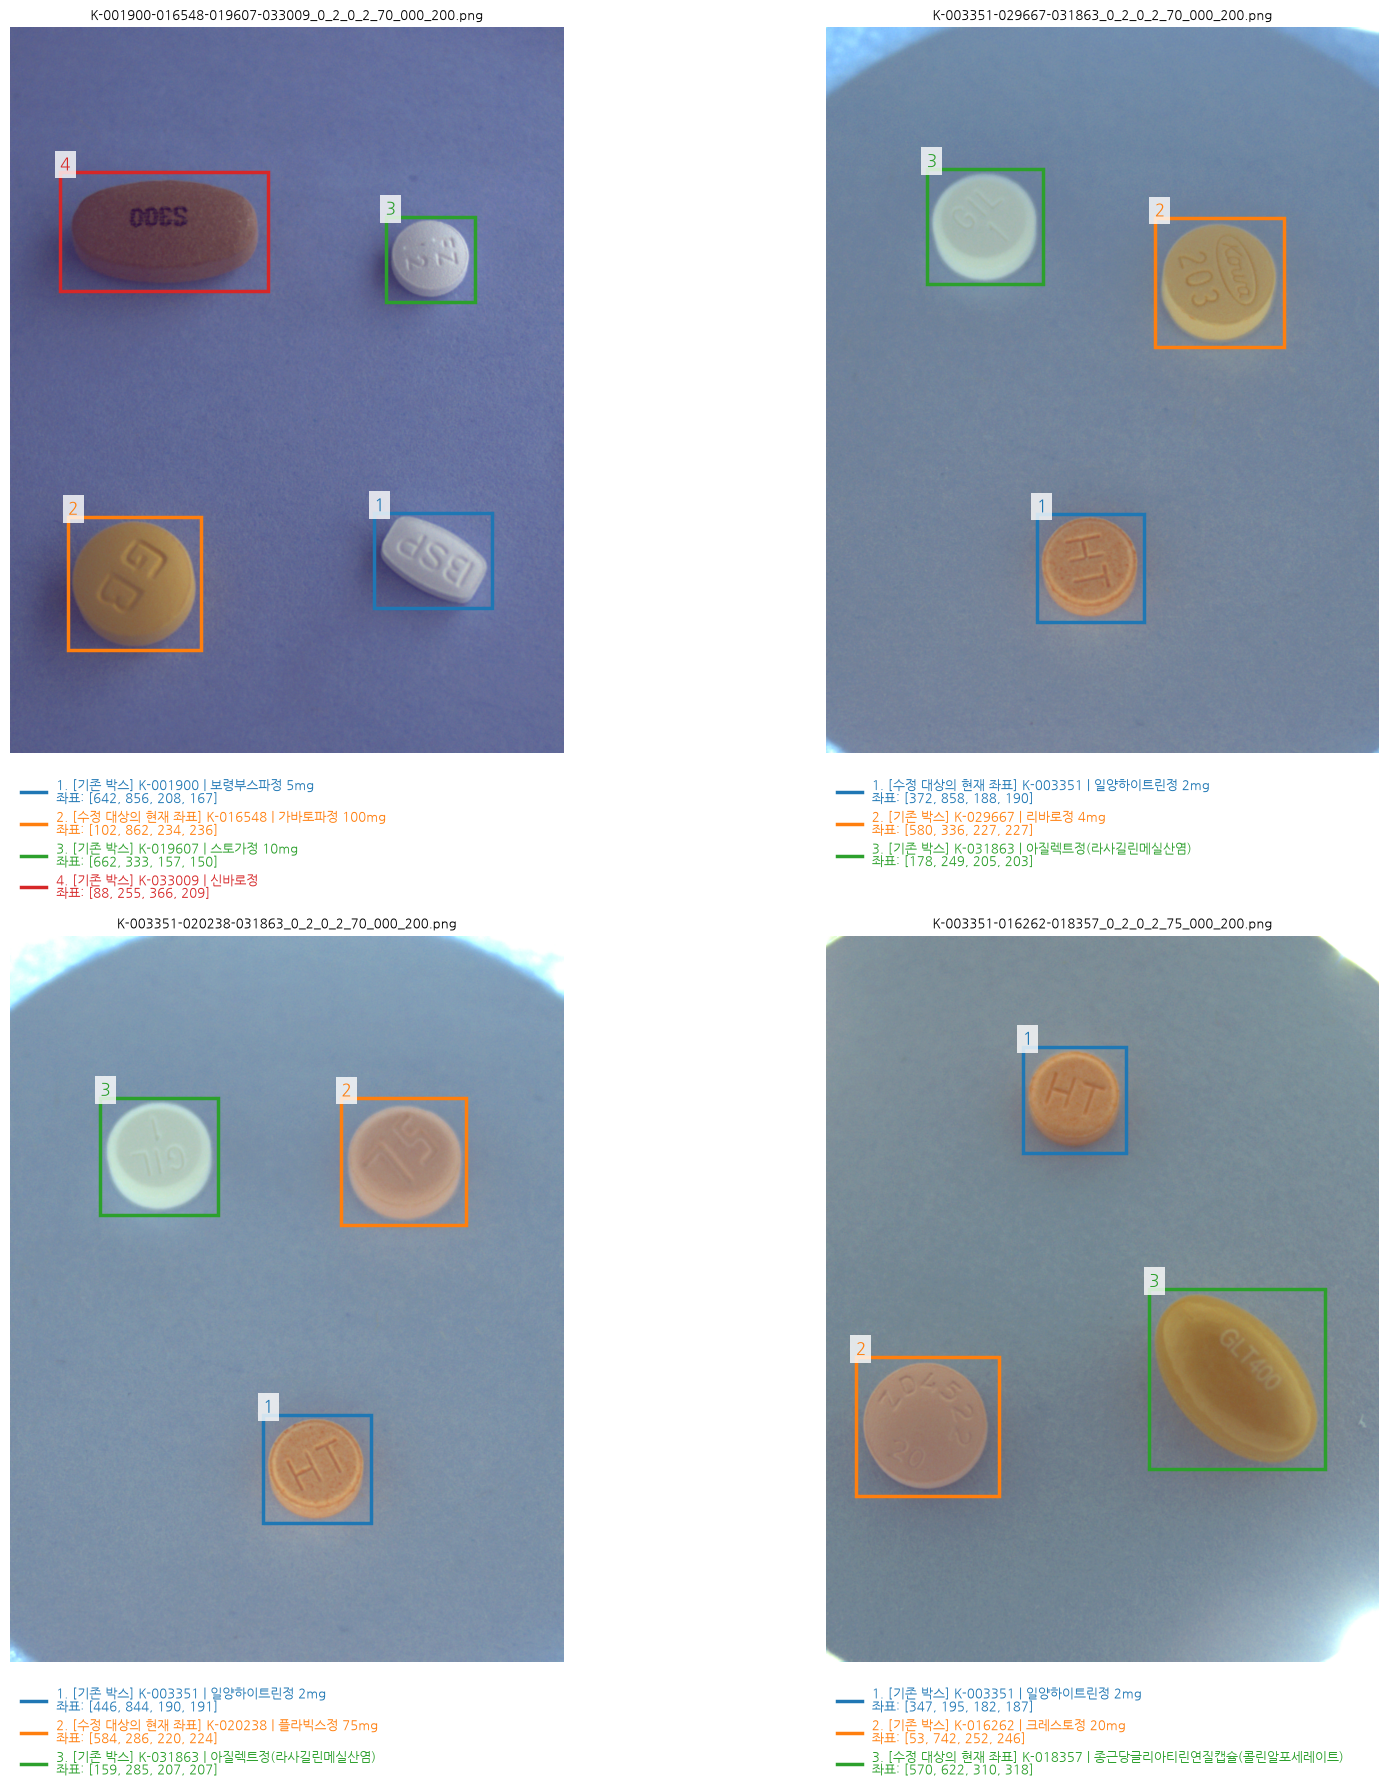

In [ ]:
root = Path.cwd()
if root.name == "notebooks":
    root = root.parent

raw_dir = root / "data" / "raw"
annotation_dir = raw_dir / "train_annotations"

targets = [
    ("K-001900-016548-019607-033009_0_2_0_2_70_000_200", "K-016548"),
    ("K-003351-029667-031863_0_2_0_2_70_000_200", "K-003351"),
    ("K-003351-020238-031863_0_2_0_2_70_000_200", "K-020238"),
    ("K-003351-016262-018357_0_2_0_2_75_000_200", "K-018357"),
]

fig, axes = plt.subplots(2, 2, figsize=(18, 18))

for ax, (stem, changed_code) in zip(axes.flat, targets):
    image_path = next((raw_dir / "train_images").rglob(f"{stem}.png"))

    with Image.open(image_path) as image:
        ax.imshow(image.convert("RGB"))

    records = []
    for path in sorted(annotation_dir.rglob(f"{stem}.json")):
        with path.open(encoding="utf-8") as file:
            data = json.load(file)

        images = {info["id"]: info for info in data["images"]}

        for ann in data["annotations"]:
            info = images[ann["image_id"]]
            if Path(info["file_name"]).stem == stem:
                records.append((info["drug_N"], info.get("dl_name") or "Unknown", ann["bbox"]))

    handles = []

    for index, (code, drug_name, bbox) in enumerate(sorted(records)):
        color = plt.get_cmap("tab10")(index % 10)
        x, y, width, height = bbox
        status = "수정 대상의 현재 좌표" if code == changed_code else "기존 박스"

        ax.add_patch(
            plt.Rectangle(
                (x, y),
                width,
                height,
                fill=False,
                edgecolor=color,
                linewidth=2.5,
            )
        )
        ax.text(
            x,
            max(0, y - 5),
            str(index + 1),
            fontsize=12,
            color=color,
            bbox={"facecolor": "white", "alpha": 0.8, "edgecolor": "none"},
        )

        handles.append(
            plt.Line2D(
                [],
                [],
                color=color,
                linewidth=2.5,
                label=f"{index + 1}. [{status}] {code} | {drug_name}\n좌표: {bbox}",
            )
        )

    ax.set_title(image_path.name, fontsize=9)
    ax.axis("off")
    ax.legend(
        handles=handles,
        loc="upper left",
        bbox_to_anchor=(0, -0.02),
        frameon=False,
        fontsize=9,
        labelcolor="linecolor",
    )

plt.tight_layout()
plt.show()

### 분석: Bounding Box 크기 분포 분석 = 객체 크기에 따른 데이터 불균형 여부를 확인하기

=== Bounding Box 크기 통계 ===
전체 Bounding Box 수: 763개


,width,height,area,area_ratio
count,763.00,763.00,763.00,763.00
mean,250.01,265.76,70384.79,5.63
std,73.77,95.65,42608.64,3.41
min,125.00,126.00,23250.00,1.86
25%,189.50,191.00,36672.00,2.94
50%,230.00,227.00,53600.00,4.29
75%,285.00,316.00,93492.50,7.48
max,529.00,664.00,272435.00,21.81



=== Bounding Box 크기별 분포 ===


,객체 수,비율(%)
size,,
Small,221,28.96
Medium,374,49.02
Large,168,22.02


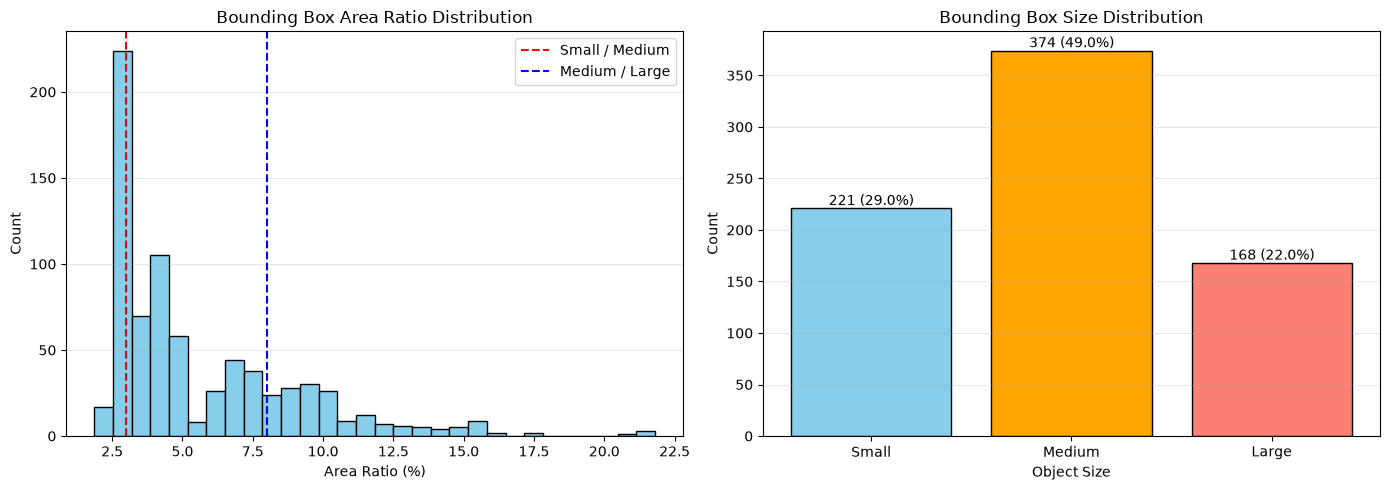

In [ ]:
# 1. 데이터 경로 설정
root = Path.cwd()

if root.name == "notebooks":
    root = root.parent

annotation_dir = root / "data" / "raw" / "train_annotations"

# 이미지 크기
image_width = 976
image_height = 1280
image_area = image_width * image_height

# 2. Bounding Box 정보 수집
bbox_records = []

for json_path in annotation_dir.rglob("*.json"):
    with open(json_path, "r", encoding="utf-8") as f:
        data = json.load(f)

    for ann in data.get("annotations", []):
        bbox = ann.get("bbox")

        if not isinstance(bbox, (list, tuple)) or len(bbox) != 4:
            continue

        x, y, w, h = bbox

        # 유효하지 않은 Bounding Box 제외
        if w <= 0 or h <= 0:
            continue

        # Bounding Box 면적
        area = w * h

        # 전체 이미지 대비 면적 비율 (%)
        area_ratio = (area / image_area) * 100

        bbox_records.append({"width": w, "height": h, "area": area, "area_ratio": area_ratio})

# 3. DataFrame 생성
df_bbox = pd.DataFrame(bbox_records)

if df_bbox.empty:
    raise ValueError("유효한 Bounding Box가 없습니다.")

# 4. 기초 통계량
print("=== Bounding Box 크기 통계 ===")
print(f"전체 Bounding Box 수: {len(df_bbox)}개")

display(df_bbox[["width", "height", "area", "area_ratio"]].describe().round(2))

# 5. Bounding Box 크기 분류
# 전체 이미지 대비 면적 비율 기준

df_bbox["size"] = pd.cut(
    df_bbox["area_ratio"],
    bins=[0, 3, 8, float("inf")],
    labels=["Small", "Medium", "Large"],
    right=False,
)

# 6. 크기별 객체 수 및 비율
size_order = ["Small", "Medium", "Large"]

size_counts = df_bbox["size"].value_counts().reindex(size_order, fill_value=0)

size_percent = size_counts / len(df_bbox) * 100

df_size = pd.DataFrame({"객체 수": size_counts, "비율(%)": size_percent.round(2)})

print("\n=== Bounding Box 크기별 분포 ===")
display(df_size)

# 7. 시각화
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# (1) Bounding Box 면적 비율 분포
axes[0].hist(df_bbox["area_ratio"], bins=30, color="skyblue", edgecolor="black")

# 크기 분류 경계선
axes[0].axvline(x=3, color="red", linestyle="--", label="Small / Medium")
axes[0].axvline(x=8, color="blue", linestyle="--", label="Medium / Large")

axes[0].set_title("Bounding Box Area Ratio Distribution")
axes[0].set_xlabel("Area Ratio (%)")
axes[0].set_ylabel("Count")
axes[0].legend()

# (2) 크기별 객체 수
axes[1].bar(
    size_counts.index, size_counts.values, color=["skyblue", "orange", "salmon"], edgecolor="black"
)

axes[1].set_title("Bounding Box Size Distribution")
axes[1].set_xlabel("Object Size")
axes[1].set_ylabel("Count")

# 막대 위에 객체 수와 비율 표시
for i, count in enumerate(size_counts.values):
    axes[1].text(i, count, f"{count} ({size_percent.iloc[i]:.1f}%)", ha="center", va="bottom")

for ax in axes:
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


### 분석: 약품 클래스별 객체 수 분포 확인하기

,값
전체 약품 클래스 수,56.00
전체 알약 객체 수,763.00
클래스당 평균 객체 수,13.62
클래스당 최소 객체 수,3.00
클래스당 최대 객체 수,153.00
클래스당 중앙값,9.00
최대 / 최소 객체 수 비율,51.00
이미지 매칭 실패,0.00
약품 코드 누락,0.00


,약품코드,약품명,객체 수,비율(%)
0,K-003351,일양하이트린정 2mg,153,20.05
1,K-003483,기넥신에프정(은행엽엑스)(수출용),45,5.90
2,K-035206,아토젯정 10/40mg,37,4.85
3,K-016262,크레스토정 20mg,23,3.01
4,K-021325,아토르바정 10mg,22,2.88
5,K-016232,리피토정 20mg,21,2.75
6,K-020238,플라빅스정 75mg,20,2.62
7,K-003832,뉴로메드정(옥시라세탐),20,2.62
8,K-036637,로수젯정10/5밀리그램,19,2.49
9,K-016548,가바토파정 100mg,18,2.36


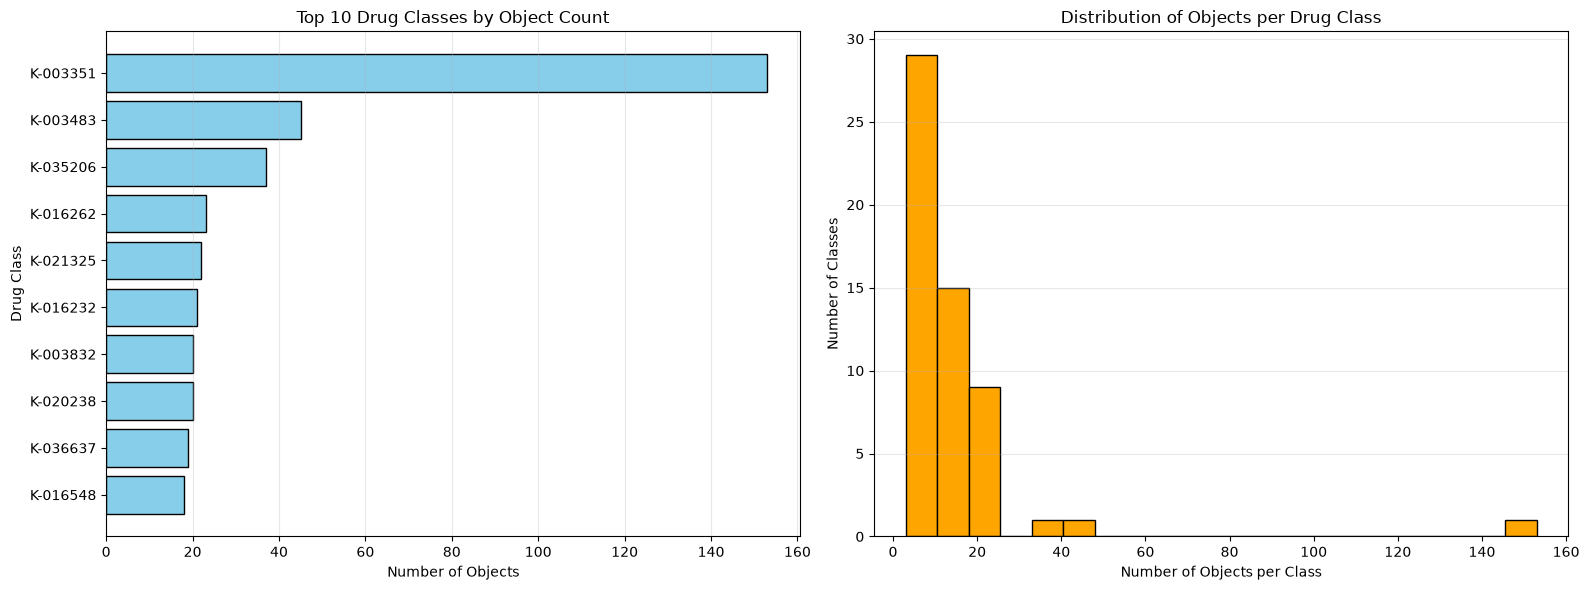

In [ ]:
# 1. 데이터 경로와 학습 이미지 목록
root = Path.cwd()
if root.name == "notebooks":
    root = root.parent

data_dir = root / "data" / "raw"
annotation_dir = data_dir / "train_annotations"
train_dir = data_dir / "train_images"

image_files = {
    path.name
    for path in train_dir.rglob("*")
    if path.is_file() and path.suffix.lower() in {".jpg", ".jpeg", ".png"}
}

# 2. 약품별 객체 수 집계
drug_counts = Counter()
drug_names = {}
unmatched_count = 0
missing_code_count = 0

for json_path in annotation_dir.rglob("*.json"):
    with json_path.open(encoding="utf-8-sig") as file:
        data = json.load(file)

    images = {img["id"]: img for img in data.get("images", [])}

    for ann in data.get("annotations", []):
        info = images.get(ann.get("image_id"))

        if info is None or Path(info.get("file_name", "")).name not in image_files:
            unmatched_count += 1
            continue

        code = info.get("drug_N")
        if not code:
            missing_code_count += 1
            continue

        drug_counts[code] += 1
        drug_names[code] = info.get("dl_name") or "Unknown"

if not drug_counts:
    raise ValueError("집계된 약품 객체가 없습니다. JSON 구조와 경로를 확인하세요.")

# 3. 클래스별 집계표
df_class = (
    pd.DataFrame(
        [
            {"약품코드": code, "약품명": drug_names[code], "객체 수": count}
            for code, count in drug_counts.items()
        ]
    )
    .sort_values("객체 수", ascending=False)
    .reset_index(drop=True)
)

counts = df_class["객체 수"]
df_class["비율(%)"] = (counts / counts.sum() * 100).round(2)

# 4. 기초 통계
summary = pd.Series(
    {
        "전체 약품 클래스 수": len(df_class),
        "전체 알약 객체 수": counts.sum(),
        "클래스당 평균 객체 수": counts.mean(),
        "클래스당 최소 객체 수": counts.min(),
        "클래스당 최대 객체 수": counts.max(),
        "클래스당 중앙값": counts.median(),
        "최대 / 최소 객체 수 비율": counts.max() / counts.min(),
        "이미지 매칭 실패": unmatched_count,
        "약품 코드 누락": missing_code_count,
    },
    name="값",
)

display(summary.to_frame().round(2))
display(df_class)

# 5. 객체 수 상위 10개 클래스와 전체 분포
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
top10 = df_class.head(10).sort_values("객체 수")

axes[0].barh(
    top10["약품코드"],
    top10["객체 수"],
    color="skyblue",
    edgecolor="black",
)
axes[0].set(
    title="Top 10 Drug Classes by Object Count",
    xlabel="Number of Objects",
    ylabel="Drug Class",
)

axes[1].hist(counts, bins=20, color="orange", edgecolor="black")
axes[1].set(
    title="Distribution of Objects per Drug Class",
    xlabel="Number of Objects per Class",
    ylabel="Number of Classes",
)

axes[0].grid(axis="x", alpha=0.3)
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### 분석: 약품 정보와 bbox 크기를 함께 확인하기

In [ ]:
# 약품 정보와 bbox 크기를 함께 수집
corrected_dir = root / "data" / "processed" / "corrected_annotations"
class_records = []

for source in annotation_dir.rglob("*.json"):
    corrected = corrected_dir / source.relative_to(annotation_dir)
    path = corrected if corrected.is_file() else source

    with path.open(encoding="utf-8-sig") as file:
        data = json.load(file)

    images = {img["id"]: img for img in data.get("images", [])}

    for ann in data.get("annotations", []):
        info = images.get(ann.get("image_id"))
        bbox = ann.get("bbox")

        if info is None or not info.get("drug_N"):
            continue
        if not isinstance(bbox, (list, tuple)) or len(bbox) != 4:
            continue

        _, _, w, h = bbox
        if w <= 0 or h <= 0:
            continue

        class_records.append(
            {
                "약품코드": info["drug_N"],
                "약품명": info.get("dl_name") or "Unknown",
                "area_ratio": w * h / image_area * 100,
            }
        )

if not class_records:
    raise ValueError("집계할 약품 bbox가 없습니다.")

df_class_bbox = pd.DataFrame(class_records)
df_class_bbox["size"] = pd.cut(
    df_class_bbox["area_ratio"],
    bins=[0, 3, 8, float("inf")],
    labels=["Small", "Medium", "Large"],
    right=False,
)

# 클래스별 사이즈 개수와 비율
size_order = ["Small", "Medium", "Large"]

class_counts = pd.crosstab(
    [df_class_bbox["약품코드"], df_class_bbox["약품명"]],
    df_class_bbox["size"],
).reindex(columns=size_order, fill_value=0)

class_percent = class_counts.div(class_counts.sum(axis=1), axis=0) * 100

df_class_size = pd.concat(
    [
        class_counts.sum(axis=1).rename("전체 객체 수"),
        class_counts.add_suffix("(개)"),
        class_percent.round(2).add_suffix("(%)"),
    ],
    axis=1,
).reset_index()

df_class_size.columns.name = None

print(f"집계된 약품 클래스: {df_class_size['약품코드'].nunique()}종")

with pd.option_context("display.max_rows", None, "display.max_colwidth", None):
    display(df_class_size)

집계된 약품 클래스: 56종


,약품코드,약품명,전체 객체 수,Small(개),Medium(개),Large(개),Small(%),Medium(%),Large(%)
0,K-001900,보령부스파정 5mg,15,15,0,0,100.00,0.00,0.00
1,K-002483,뮤테란캡슐 100mg,9,0,1,8,0.00,11.11,88.89
2,K-003351,일양하이트린정 2mg,153,153,0,0,100.00,0.00,0.00
3,K-003483,기넥신에프정(은행엽엑스)(수출용),45,0,45,0,0.00,100.00,0.00
4,K-003544,무코스타정(레바미피드)(비매품),6,0,6,0,0.00,100.00,0.00
5,K-003743,알드린정,3,0,1,2,0.00,33.33,66.67
6,K-003832,뉴로메드정(옥시라세탐),20,0,0,20,0.00,0.00,100.00
7,K-004543,에어탈정(아세클로페낙),5,0,5,0,0.00,100.00,0.00
8,K-012081,리렉스펜정 300mg/PTP,3,0,1,2,0.00,33.33,66.67
9,K-012247,아빌리파이정 10mg,3,3,0,0,100.00,0.00,0.00
